# ACL Seminar 3 – Zipf's Law Corpus Experiment
## Final Experimental Results for Course DOCX Presentation

**Student:** Todoran Ciprian Bogdan  
**Academic Year:** 2025–2026 | **Course:** Applied Computational Linguistics (ACL)  
**Institution:** Faculty of Engineering and Information Technology / University of Medicine, Pharmacy, Science and Technology "George Emil Palade" of Târgu Mureș

---

### Objectives & Scope
This notebook performs a comparative statistical corpus study investigating **Zipf's Law** across three authentic linguistic corpora:
1. **English (EN):** *Frankenstein* by Mary Shelley (Project Gutenberg #84)
2. **Italian (IT):** *Le avventure di Pinocchio* by Carlo Collodi (Project Gutenberg #52484)
3. **Romanian (RO):** *Bachelor's Degree Thesis* by Todoran Ciprian Bogdan (2023)

### Professor's Required Results Structure (Columns 1 to 6)
1. **Student:** Student Full Name
2. **Corpus source / Corpus dimension:** Source title and counts of total tokens ($N$) and unique types ($V$).
3. **Zipf graph:** Linear graphical representation of absolute frequency vs. rank for the top 200 most frequent words.
4. **The most frequent 7 words:** Top 7 words in descending frequency order with exact occurrence counts: `("word":frequency)`.
5. **Percentage of tokens covered by top 7 words:** $rac{\sum_{i=1}^7 f_i}{N} 	imes 100\%$.
6. **Percentage of words appearing once (Hapax Legomena):** Count of singletons, percentage of total corpus tokens, and percentage of vocabulary types.

In [1]:
import os
import sys
import json
import re
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display

# Configure matplotlib high-resolution output
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

# Workspace paths
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_RAW = PROJECT_ROOT / "data" / "raw"
RESULTS_FINAL = PROJECT_ROOT / "results" / "final_results"
GRAPHS_DIR = RESULTS_FINAL / "graphs"

RESULTS_FINAL.mkdir(parents=True, exist_ok=True)
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

STUDENT_NAME = "Todoran Ciprian Bogdan"
print(f"Environment initialized.")
print(f"Project root: {PROJECT_ROOT}")
print(f"Results directory: {RESULTS_FINAL}")
print(f"Student: {STUDENT_NAME}")

Environment initialized.
Project root: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3
Results directory: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\final_results
Student: Todoran Ciprian Bogdan


## 1. Corpus Sources

The experiment compares three distinct corpora in three languages:
- **Corpus 1 (EN):** `data/raw/frankenstein.txt` (Classic English Literary Prose)
- **Corpus 2 (IT):** `data/raw/pinocchio.txt` (Classic Italian Literary Prose)
- **Corpus 3 (RO):** `data/raw/licenta_todoran.txt` (Modern Romanian Technical Prose)

In [2]:
CORPUS_FILES = {
    "EN": {
        "title": "Frankenstein",
        "author": "Mary Shelley",
        "lang": "English",
        "path": DATA_RAW / "frankenstein.txt",
        "is_gutenberg": True,
        "is_thesis": False,
        "color": "#1f77b4"
    },
    "IT": {
        "title": "Pinocchio",
        "author": "Carlo Collodi",
        "lang": "Italian",
        "path": DATA_RAW / "pinocchio.txt",
        "is_gutenberg": True,
        "is_thesis": False,
        "color": "#2ca02c"
    },
    "RO": {
        "title": "Bachelor Thesis",
        "author": "Todoran Ciprian Bogdan",
        "lang": "Romanian",
        "path": DATA_RAW / "licenta_todoran.txt",
        "is_gutenberg": False,
        "is_thesis": True,
        "color": "#d62728"
    }
}

raw_corpora = {}
for code, meta in CORPUS_FILES.items():
    if not meta["path"].exists():
        raise FileNotFoundError(f"Missing corpus file: {meta['path']}")
    text = meta["path"].read_text(encoding="utf-8", errors="replace")
    raw_corpora[code] = text
    print(f"[{code}] {meta['title']} ({meta['lang']}): {len(text):,} characters loaded from {meta['path'].name}")

[EN] Frankenstein (English): 446,582 characters loaded from frankenstein.txt
[IT] Pinocchio (Italian): 282,323 characters loaded from pinocchio.txt
[RO] Bachelor Thesis (Romanian): 67,201 characters loaded from licenta_todoran.txt


## 2. Text Preprocessing & Word Tokenization

A unified, reproducible preprocessing pipeline is applied to all three texts:
1. **Gutenberg Boilerplate Removal:** For Frankenstein and Pinocchio, standard header and license footers are excised.
2. **LaTeX Diacritic Restoration:** For the technical thesis, broken LaTeX/PDF accent representations (`˘ a` $\rightarrow$ `ă`, `ˆ i` $\rightarrow$ `î`, `s, ` $\rightarrow$ `ș`, `t, ` $\rightarrow$ `ț`) are standardized.
3. **Unicode NFC Normalization:** Combines split accents into precomposed characters.
4. **Apostrophe Standardization:** Curly apostrophes (`’`, `‘`) converted to ASCII single quotes.
5. **Lowercasing:** Uniform lowercase representation.
6. **Word Tokenization:** Matches continuous alphabetic characters including Latin-1 and Romanian diacritics (`[a-zà-öø-ÿăâîșț]`), preserving internal apostrophes (e.g., *l'avventura*, *don't*).
7. **Stopwords Retained:** Function words are preserved to capture authentic natural language distribution.

In [3]:
def remove_gutenberg_boilerplate(text: str) -> str:
    start_match = re.search(r"\*\*\*\s*START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK[^\n]*\*\*\*", text, re.IGNORECASE)
    end_match = re.search(r"\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK[^\n]*\*\*\*|End of (?:the )?Project Gutenberg", text, re.IGNORECASE)
    start_idx = start_match.end() if start_match else 0
    end_idx = end_match.start() if end_match else len(text)
    return text[start_idx:end_idx]

TOKEN_REGEX = re.compile(r"[a-zà-öø-ÿăâîșț]+(?:'[a-zà-öø-ÿăâîșț]+)*")

def preprocess_and_tokenize(text: str, is_gutenberg: bool = False, is_thesis: bool = False) -> list[str]:
    if is_gutenberg:
        text = remove_gutenberg_boilerplate(text)
    if is_thesis:
        text = re.sub(r'˘\s*a', 'ă', text)
        text = re.sub(r'˘\s*A', 'Ă', text)
        text = re.sub(r'ˆ\s*ı', 'î', text)
        text = re.sub(r'ˆ\s*i', 'î', text)
        text = re.sub(r'ˆ\s*I', 'Î', text)
        text = re.sub(r'ˆ\s*a', 'â', text)
        text = re.sub(r'ˆ\s*A', 'Â', text)
        text = re.sub(r's,\s*', 'ș', text)
        text = re.sub(r'S,\s*', 'Ș', text)
        text = re.sub(r't,\s*', 'ț', text)
        text = re.sub(r'T,\s*', 'Ț', text)
    
    text = unicodedata.normalize("NFC", text)
    text = text.replace("’", "'").replace("‘", "'").replace("`", "'").lower()
    return TOKEN_REGEX.findall(text)

tokenized_corpora = {}
for code, meta in CORPUS_FILES.items():
    tokens = preprocess_and_tokenize(
        raw_corpora[code], 
        is_gutenberg=meta["is_gutenberg"], 
        is_thesis=meta["is_thesis"]
    )
    tokenized_corpora[code] = tokens
    print(f"[{code}] {meta['title']}: {len(tokens):,} tokens | {len(set(tokens)):,} unique types | Sample: {tokens[:8]}")

[EN] Frankenstein: 75,201 tokens | 7,013 unique types | Sample: ['frankenstein', 'or', 'the', 'modern', 'prometheus', 'by', 'mary', 'wollstonecraft']
[IT] Pinocchio: 41,525 tokens | 6,215 unique types | Sample: ['c', 'collodi', 'le', 'avventure', 'di', 'pinocchio', 'storia', 'di']
[RO] Bachelor Thesis: 8,301 tokens | 2,056 unique types | Sample: ['universitatea', 'de', 'medicină', 'f', 'armacie', 'științe', 'și', 'tehnologie']


## 3. Corpus Dimensions & Lexical Diversity

Below is the dimension summary for the three corpora, displaying:
- **Tokens ($N$):** Total running words.
- **Types ($V$):** Vocabulary size (unique word forms).
- **Type-Token Ratio ($TTR = V / N$):** Standard measure of lexical diversity.

In [4]:
dim_rows = []
for code, meta in CORPUS_FILES.items():
    toks = tokenized_corpora[code]
    n = len(toks)
    v = len(set(toks))
    ttr = v / n if n > 0 else 0
    dim_rows.append({
        "Language": meta["lang"],
        "Code": code,
        "Corpus Title": meta["title"],
        "Author": meta["author"],
        "Tokens (N)": f"{n:,}",
        "Types (V)": f"{v:,}",
        "Raw Tokens": n,
        "Raw Types": v,
        "TTR": round(ttr, 4)
    })

dim_df = pd.DataFrame(dim_rows)
dim_df.to_csv(RESULTS_FINAL / "corpus_statistics.csv", index=False)
display(HTML("<h3>Corpus Dimension Summary</h3>"))
display(dim_df[["Language", "Code", "Corpus Title", "Author", "Tokens (N)", "Types (V)", "TTR"]])

,Language,Code,Corpus Title,Author,Tokens (N),Types (V),TTR
0,English,EN,Frankenstein,Mary Shelley,"75,201","7,013",0.0933
1,Italian,IT,Pinocchio,Carlo Collodi,"41,525","6,215",0.1497
2,Romanian,RO,Bachelor Thesis,Todoran Ciprian Bogdan,"8,301","2,056",0.2477


## 4. Deterministic Word Frequency Ranking & Top 7 Words

Words are counted and sorted deterministically:
1. **Descending frequency** (highest occurrence first).
2. **Ascending alphabetical order** (to break equal-frequency ties unambiguously).

The **percentage of corpus tokens covered by the top 7 words** is calculated as:
$$\text{Coverage}_{\text{top 7}} = \frac{\sum_{i=1}^7 f_i}{N} \times 100\%$$

In [5]:
freq_dfs = {}
top7_data = {}
top7_csv_records = []

for code, meta in CORPUS_FILES.items():
    toks = tokenized_corpora[code]
    n = len(toks)
    counts = Counter(toks)
    sorted_items = sorted(counts.items(), key=lambda x: (-x[1], x[0]))
    
    rows = []
    cum = 0
    for r, (w, f) in enumerate(sorted_items, 1):
        cum += f
        rows.append({
            "rank": r,
            "word": w,
            "frequency": f,
            "relative_freq": f / n,
            "cum_frequency": cum,
            "cum_pct": cum / n * 100
        })
    
    fdf = pd.DataFrame(rows)
    freq_dfs[code] = fdf
    fdf.to_csv(RESULTS_FINAL / f"{code.lower()}_frequencies.csv", index=False)
    
    top7_list = sorted_items[:7]
    top7_sum = sum(f for _, f in top7_list)
    cov_pct = (top7_sum / n * 100) if n > 0 else 0
    
    formatted_top7 = ", ".join(f'("{w}":{f})' for w, f in top7_list)
    top7_data[code] = {
        "list": top7_list,
        "sum": top7_sum,
        "coverage_pct": cov_pct,
        "formatted": formatted_top7
    }
    
    for rank, (w, f) in enumerate(top7_list, 1):
        top7_csv_records.append({
            "language_code": code,
            "corpus": meta["title"],
            "rank": rank,
            "word": w,
            "frequency": f,
            "pct_of_corpus": round(f / n * 100, 3)
        })

top7_df = pd.DataFrame(top7_csv_records)
top7_df.to_csv(RESULTS_FINAL / "top7_words.csv", index=False)

print("--- Top 7 Most Frequent Words ---")
for code, meta in CORPUS_FILES.items():
    print(f"{code} ({meta['title']}): {top7_data[code]['formatted']}")
    print(f"    Coverage: {top7_data[code]['coverage_pct']:.2f}% ({top7_data[code]['sum']:,} / {len(tokenized_corpora[code]):,} tokens)\n")

--- Top 7 Most Frequent Words ---
EN (Frankenstein): ("the":4195), ("and":2976), ("i":2850), ("of":2642), ("to":2094), ("my":1776), ("a":1391)
    Coverage: 23.83% (17,924 / 75,201 tokens)

IT (Pinocchio): ("e":1788), ("di":1390), ("che":1042), ("a":977), ("il":965), ("la":742), ("un":738)
    Coverage: 18.40% (7,642 / 41,525 tokens)

RO (Bachelor Thesis): ("de":351), ("în":281), ("a":209), ("și":168), ("m":165), ("pentru":119), ("un":107)
    Coverage: 16.87% (1,400 / 8,301 tokens)



## 5. Hapax Legomena Analysis (Words Appearing Exactly Once)

A **hapax legomenon** is a word type that occurs exactly once in a corpus ($f = 1$).
We calculate:
1. **Count of Hapax Types ($V_1$):** Total singleton words.
2. **Percentage of Tokens:** $\frac{V_1}{N} \times 100\%$ (each occurs once, so tokens = types = $V_1$).
3. **Percentage of Types:** $\frac{V_1}{V} \times 100\%$.

In [6]:
hapax_data = {}
hapax_records = []

for code, meta in CORPUS_FILES.items():
    toks = tokenized_corpora[code]
    n = len(toks)
    v = len(set(toks))
    counts = Counter(toks)
    
    hapax_count = sum(1 for _, f in counts.items() if f == 1)
    pct_tokens = (hapax_count / n * 100) if n > 0 else 0
    pct_types = (hapax_count / v * 100) if v > 0 else 0
    
    formatted_str = f"{hapax_count:,}, {pct_tokens:.2f}% of the tokens, {pct_types:.2f}% of the types"
    hapax_data[code] = {
        "count": hapax_count,
        "pct_tokens": pct_tokens,
        "pct_types": pct_types,
        "formatted": formatted_str
    }
    
    hapax_records.append({
        "Language": meta["lang"],
        "Code": code,
        "Corpus": meta["title"],
        "Hapax Count (V1)": f"{hapax_count:,}",
        "Hapax % of Tokens": f"{pct_tokens:.2f}%",
        "Hapax % of Types": f"{pct_types:.2f}%",
        "Raw Count": hapax_count,
        "Raw Pct Tokens": pct_tokens,
        "Raw Pct Types": pct_types
    })

hapax_df = pd.DataFrame(hapax_records)
hapax_df.to_csv(RESULTS_FINAL / "hapax_analysis.csv", index=False)

display(HTML("<h3>Hapax Legomena Statistical Summary</h3>"))
display(hapax_df[["Language", "Code", "Corpus", "Hapax Count (V1)", "Hapax % of Tokens", "Hapax % of Types"]])

,Language,Code,Corpus,Hapax Count (V1),Hapax % of Tokens,Hapax % of Types
0,English,EN,Frankenstein,"3,015",4.01%,42.99%
1,Italian,IT,Pinocchio,"3,302",7.95%,53.13%
2,Romanian,RO,Bachelor Thesis,"1,138",13.71%,55.35%


Saved: zipf_en_top200.png
Saved: zipf_it_top200.png


Saved: zipf_ro_top200.png


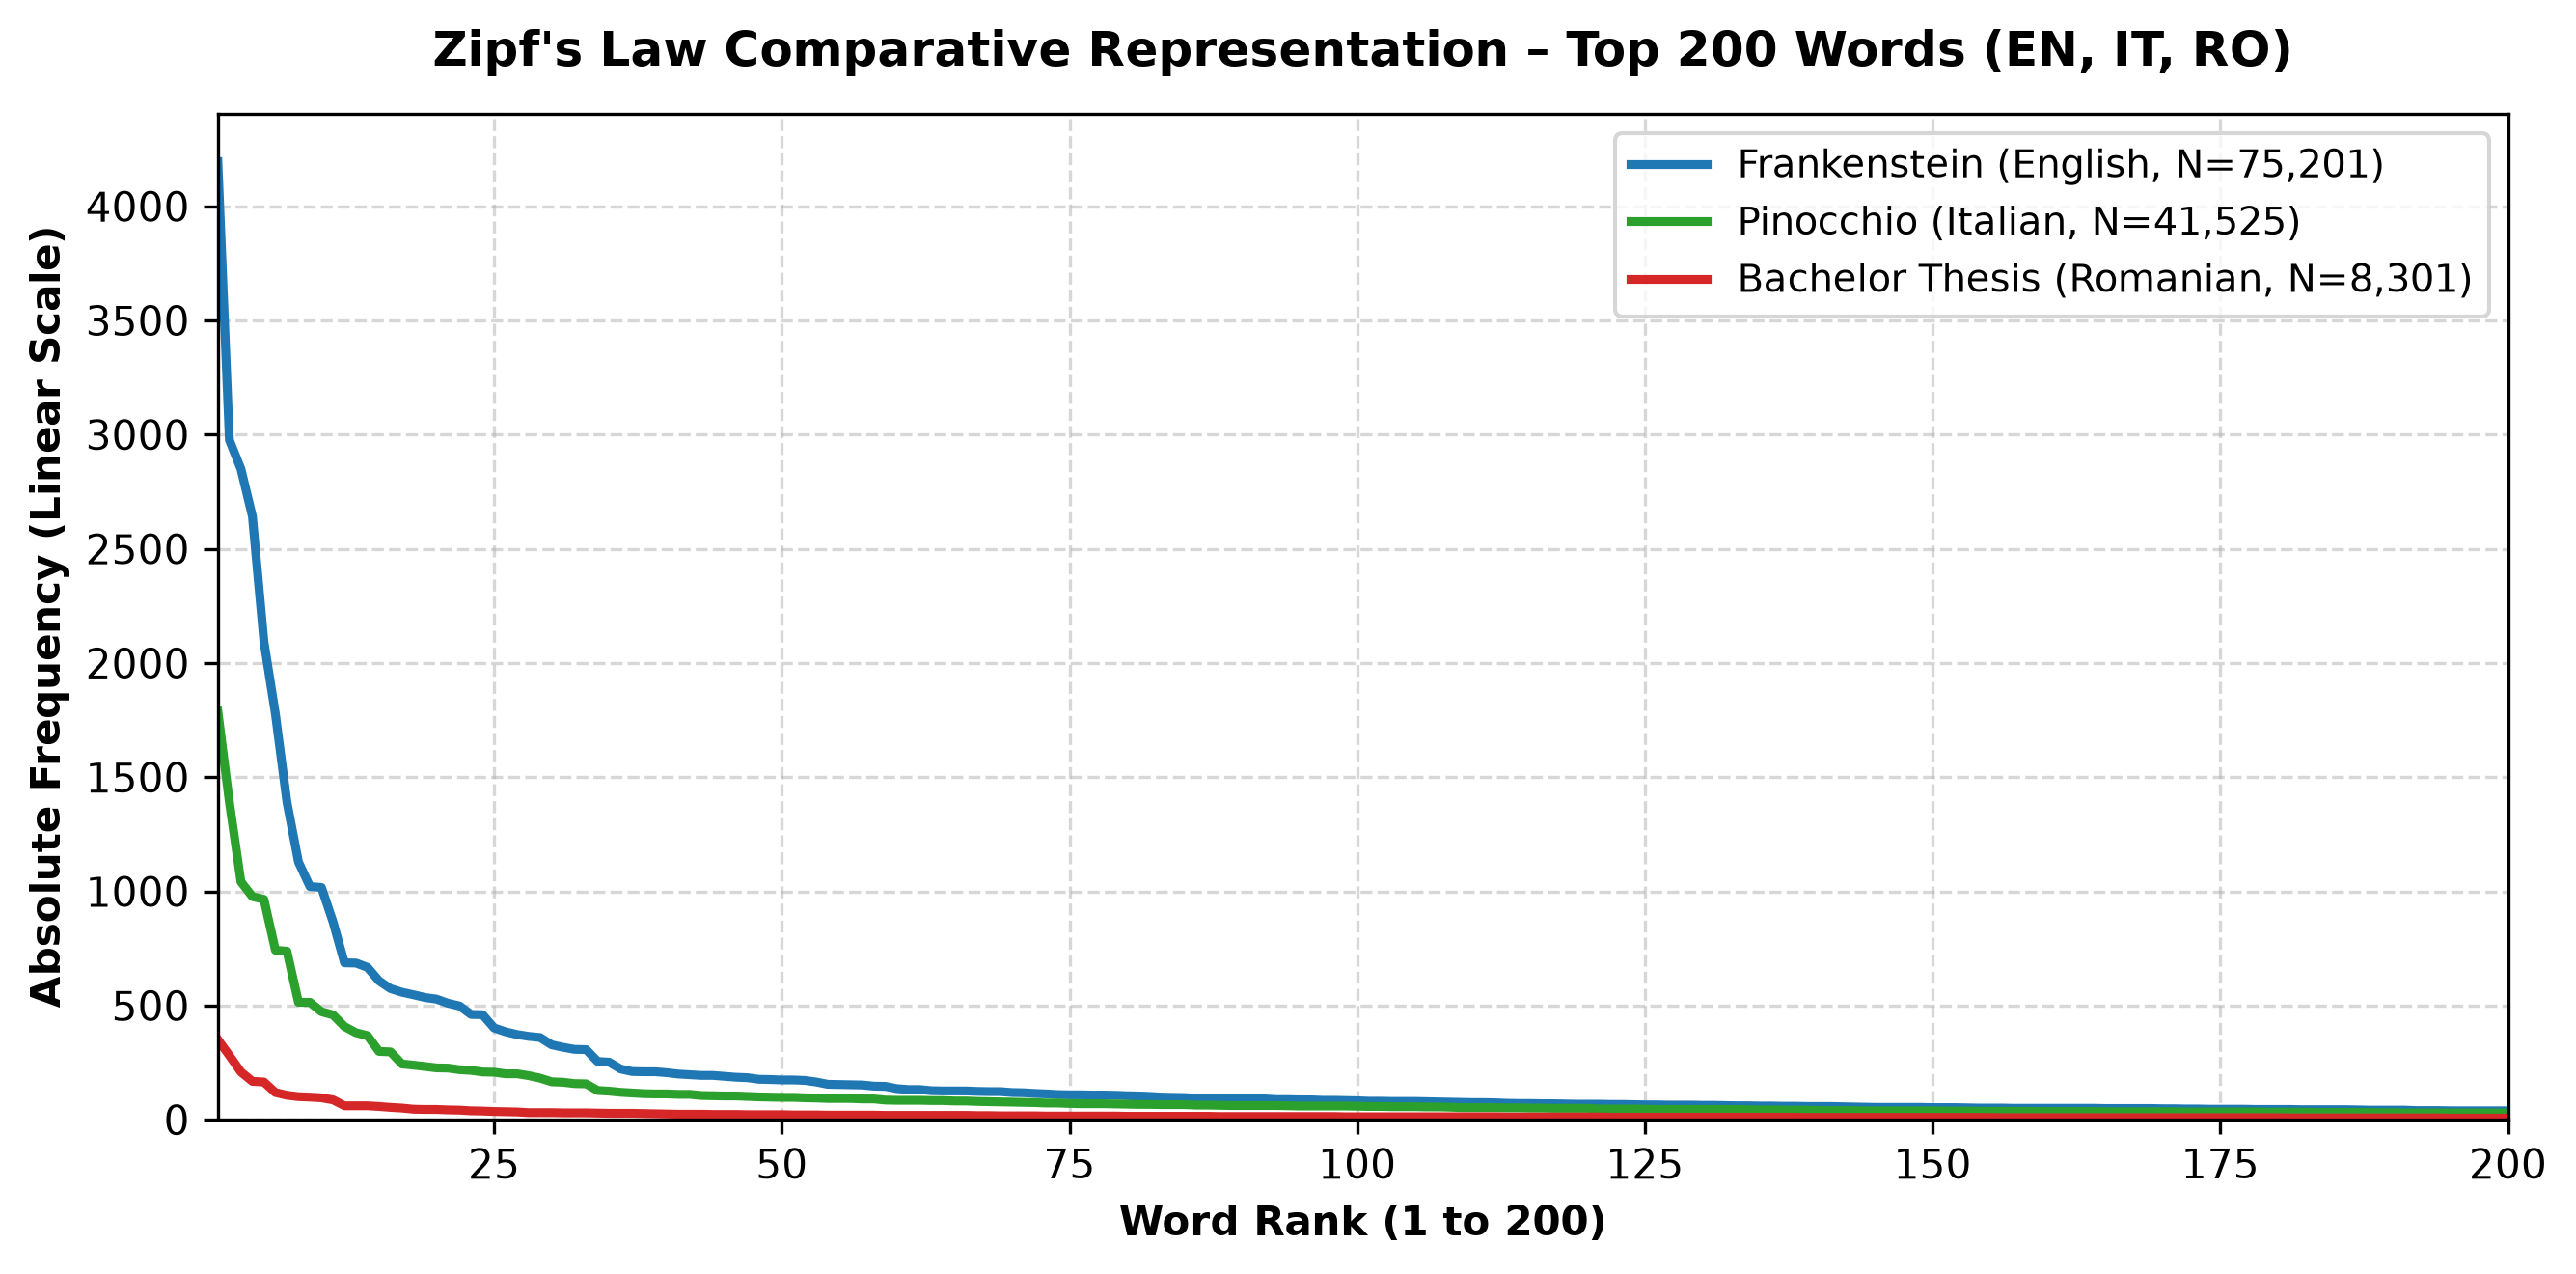

Saved combined graph: zipf_top200_combined.png


In [7]:
# Generate High-Resolution Linear Zipf Graphs (Top 200 words)

# 1. Individual 300 DPI Top 200 Graphs for each corpus
graph_paths = {}
for code, meta in CORPUS_FILES.items():
    fdf = freq_dfs[code]
    top200 = fdf.head(200)
    
    fig, ax = plt.subplots(figsize=(7, 3.8), dpi=300)
    ax.plot(top200["rank"], top200["frequency"], color=meta["color"], lw=2.2, label=f"{meta['title']} ({code})")
    ax.fill_between(top200["rank"], top200["frequency"], color=meta["color"], alpha=0.15)
    
    # Annotate Top 1 word
    top1 = top200.iloc[0]
    ax.annotate(f"Rank 1: '{top1['word']}' ({top1['frequency']:,})",
                xy=(top1["rank"], top1["frequency"]),
                xytext=(top1["rank"] + 15, top1["frequency"] * 0.88),
                arrowprops=dict(facecolor=meta["color"], shrink=0.08, width=1.2, headwidth=6),
                fontsize=9, fontweight="bold", color="#222222")
    
    ax.set_title(f"Zipf's Law Top 200 Words – {meta['title']} ({meta['lang']})", fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Word Rank (1 to 200)", fontsize=10, fontweight="bold")
    ax.set_ylabel("Absolute Frequency", fontsize=10, fontweight="bold")
    ax.set_xlim(1, 200)
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(frameon=True, facecolor="white", loc="upper right", fontsize=9)
    plt.tight_layout()
    
    out_img = GRAPHS_DIR / f"zipf_{code.lower()}_top200.png"
    plt.savefig(out_img, dpi=300, bbox_inches="tight")
    graph_paths[code] = out_img
    plt.close()
    print(f"Saved: {out_img.name}")

# 2. Combined 3-in-1 Comparison Graph
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)
for code, meta in CORPUS_FILES.items():
    fdf = freq_dfs[code]
    top200 = fdf.head(200)
    ax.plot(top200["rank"], top200["frequency"], color=meta["color"], lw=2.2, label=f"{meta['title']} ({meta['lang']}, N={len(tokenized_corpora[code]):,})")

ax.set_title("Zipf's Law Comparative Representation – Top 200 Words (EN, IT, RO)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Word Rank (1 to 200)", fontsize=10, fontweight="bold")
ax.set_ylabel("Absolute Frequency (Linear Scale)", fontsize=10, fontweight="bold")
ax.set_xlim(1, 200)
ax.set_ylim(bottom=0)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True, facecolor="white", loc="upper right", fontsize=9.5)
plt.tight_layout()

combined_img = GRAPHS_DIR / "zipf_top200_combined.png"
plt.savefig(combined_img, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved combined graph: {combined_img.name}")

## 6. Professor's Required Results Table

The consolidated multi-corpus results table below matches the exact column structure requested by the professor:
1. **Student**
2. **Corpus source / Corpus dimension** (- no of tokens, - no of types)
3. **Zipf -> graphic representation for top 200 most frequent words**
4. **The most freq. 7 words (in order)**
5. **Percent of the tokens in the corpus covered by the most freq. 7 words**
6. **Percent of the words in the corpus covered by words that appear once (- as types, - as tokens)**

In [8]:
# Build formatted string representations matching professor's sample

col2_text = (
    f"EN: Frankenstein:\n"
    f"{len(tokenized_corpora['EN']):,} tokens, {len(set(tokenized_corpora['EN'])):,} types;\n"
    f"IT: Pinocchio:\n"
    f"{len(tokenized_corpora['IT']):,} tokens, {len(set(tokenized_corpora['IT'])):,} types;\n"
    f"RO: Bachelor Thesis:\n"
    f"{len(tokenized_corpora['RO']):,} tokens, {len(set(tokenized_corpora['RO'])):,} types."
)

col4_text = (
    f"EN: {top7_data['EN']['formatted']}\n"
    f"IT: {top7_data['IT']['formatted']}\n"
    f"RO: {top7_data['RO']['formatted']}"
)

col5_text = (
    f"EN: {top7_data['EN']['coverage_pct']:.2f}%\n"
    f"IT: {top7_data['IT']['coverage_pct']:.2f}%\n"
    f"RO: {top7_data['RO']['coverage_pct']:.2f}%"
)

col6_text = (
    f"EN: {hapax_data['EN']['formatted']}\n"
    f"IT: {hapax_data['IT']['formatted']}\n"
    f"RO: {hapax_data['RO']['formatted']}"
)

html_table = f"""
<div style="font-family: Arial, sans-serif; margin-top: 15px;">
<table style="width: 100%; border-collapse: collapse; border: 2px solid #333333; font-size: 13px;">
    <thead style="background-color: #2b4c7e; color: #ffffff;">
        <tr>
            <th style="padding: 10px; border: 1px solid #333; width: 4%;">#</th>
            <th style="padding: 10px; border: 1px solid #333; width: 14%;">Student</th>
            <th style="padding: 10px; border: 1px solid #333; width: 18%;">Corpus source<br>Corpus dimension</th>
            <th style="padding: 10px; border: 1px solid #333; width: 22%;">Zipf graph<br>(top 200 words)</th>
            <th style="padding: 10px; border: 1px solid #333; width: 22%;">The most freq. 7 words<br>(in order)</th>
            <th style="padding: 10px; border: 1px solid #333; width: 10%;">% tokens covered by top 7 words</th>
            <th style="padding: 10px; border: 1px solid #333; width: 10%;">% words appearing once<br>(as types / as tokens)</th>
        </tr>
    </thead>
    <tbody>
        <tr style="background-color: #fdfdfd; vertical-align: top;">
            <td style="padding: 8px; border: 1px solid #ccc; font-weight: bold; text-align: center;">1</td>
            <td style="padding: 8px; border: 1px solid #ccc; font-weight: bold;">{STUDENT_NAME}</td>
            <td style="padding: 8px; border: 1px solid #ccc; white-space: pre-line; line-height: 1.45;"><b>EN: Frankenstein:</b><br>{len(tokenized_corpora['EN']):,} tokens, {len(set(tokenized_corpora['EN'])):,} types;<br><br><b>IT: Pinocchio:</b><br>{len(tokenized_corpora['IT']):,} tokens, {len(set(tokenized_corpora['IT'])):,} types;<br><br><b>RO: Bachelor Thesis:</b><br>{len(tokenized_corpora['RO']):,} tokens, {len(set(tokenized_corpora['RO'])):,} types.</td>
            <td style="padding: 8px; border: 1px solid #ccc; text-align: center;">
                <img src="../results/final_results/graphs/zipf_top200_combined.png" style="width: 100%; max-width: 260px; border: 1px solid #bbb; border-radius: 4px;" alt="Zipf Top 200"><br>
                <small style="color: #555;">Combined Top 200 (EN, IT, RO)</small>
            </td>
            <td style="padding: 8px; border: 1px solid #ccc; font-size: 11px; line-height: 1.5; font-family: monospace;">
                <b style="font-family: sans-serif; color: #1f77b4;">EN:</b><br>{top7_data['EN']['formatted']}<br><br>
                <b style="font-family: sans-serif; color: #2ca02c;">IT:</b><br>{top7_data['IT']['formatted']}<br><br>
                <b style="font-family: sans-serif; color: #d62728;">RO:</b><br>{top7_data['RO']['formatted']}
            </td>
            <td style="padding: 8px; border: 1px solid #ccc; font-weight: bold; line-height: 1.8;">
                <span style="color: #1f77b4;">EN:</span> {top7_data['EN']['coverage_pct']:.2f}%<br>
                <span style="color: #2ca02c;">IT:</span> {top7_data['IT']['coverage_pct']:.2f}%<br>
                <span style="color: #d62728;">RO:</span> {top7_data['RO']['coverage_pct']:.2f}%
            </td>
            <td style="padding: 8px; border: 1px solid #ccc; font-size: 11px; line-height: 1.5;">
                <b style="color: #1f77b4;">EN:</b><br>{hapax_data['EN']['count']:,}<br>{hapax_data['EN']['pct_tokens']:.2f}% tokens<br>{hapax_data['EN']['pct_types']:.2f}% types<br><br>
                <b style="color: #2ca02c;">IT:</b><br>{hapax_data['IT']['count']:,}<br>{hapax_data['IT']['pct_tokens']:.2f}% tokens<br>{hapax_data['IT']['pct_types']:.2f}% types<br><br>
                <b style="color: #d62728;">RO:</b><br>{hapax_data['RO']['count']:,}<br>{hapax_data['RO']['pct_tokens']:.2f}% tokens<br>{hapax_data['RO']['pct_types']:.2f}% types
            </td>
        </tr>
    </tbody>
</table>
</div>
"""

display(HTML(html_table))

#,Student,Corpus sourceCorpus dimension,Zipf graph(top 200 words),The most freq. 7 words(in order),% tokens covered by top 7 words,% words appearing once(as types / as tokens)
1,Todoran Ciprian Bogdan,"EN: Frankenstein:75,201 tokens, 7,013 types;IT: Pinocchio:41,525 tokens, 6,215 types;RO: Bachelor Thesis:8,301 tokens, 2,056 types.","Combined Top 200 (EN, IT, RO)","EN:(""the"":4195), (""and"":2976), (""i"":2850), (""of"":2642), (""to"":2094), (""my"":1776), (""a"":1391) IT:(""e"":1788), (""di"":1390), (""che"":1042), (""a"":977), (""il"":965), (""la"":742), (""un"":738) RO:(""de"":351), (""în"":281), (""a"":209), (""și"":168), (""m"":165), (""pentru"":119), (""un"":107)",EN: 23.83% IT: 18.40% RO: 16.87%,"EN:3,0154.01% tokens42.99% types IT:3,3027.95% tokens53.13% types RO:1,13813.71% tokens55.35% types"


In [9]:
# 1. Export JSON Experiment Results
experiment_payload = {
    "execution_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "student": STUDENT_NAME,
    "corpora": {}
}

for code, meta in CORPUS_FILES.items():
    toks = tokenized_corpora[code]
    n = len(toks)
    v = len(set(toks))
    experiment_payload["corpora"][code] = {
        "title": meta["title"],
        "author": meta["author"],
        "language": meta["lang"],
        "total_tokens": n,
        "total_unique_types": v,
        "ttr": round(v / n, 4) if n > 0 else 0,
        "top_7_words": top7_data[code]["list"],
        "top_7_coverage_pct": round(top7_data[code]["coverage_pct"], 2),
        "hapax_legomena": {
            "hapax_count": hapax_data[code]["count"],
            "pct_tokens": round(hapax_data[code]["pct_tokens"], 2),
            "pct_types": round(hapax_data[code]["pct_types"], 2)
        },
        "zipf_graph": str(graph_paths[code].relative_to(PROJECT_ROOT))
    }

json_path = RESULTS_FINAL / "experiment_results.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(experiment_payload, f, indent=2, ensure_ascii=False)
print(f"Exported JSON Results -> {json_path.name}")

# 2. Export Consolidated Comparison CSV
comparison_rows = []
for code, meta in CORPUS_FILES.items():
    comparison_rows.append({
        "Language": meta["lang"],
        "Code": code,
        "Corpus Source": meta["title"],
        "Author": meta["author"],
        "Tokens": len(tokenized_corpora[code]),
        "Types": len(set(tokenized_corpora[code])),
        "TTR": round(len(set(tokenized_corpora[code])) / len(tokenized_corpora[code]), 4),
        "Top Word": f"'{top7_data[code]['list'][0][0]}' ({top7_data[code]['list'][0][1]})",
        "Top 7 Coverage": f"{top7_data[code]['coverage_pct']:.2f}%",
        "Hapax Count": hapax_data[code]["count"],
        "Hapax % Tokens": f"{hapax_data[code]['pct_tokens']:.2f}%",
        "Hapax % Types": f"{hapax_data[code]['pct_types']:.2f}%"
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(RESULTS_FINAL / "final_comparison.csv", index=False)
print("Exported final_comparison.csv")

# 3. Generate Landscape DOCX Document for Seminar Presentation
import docx
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_ALIGN_VERTICAL
from docx.enum.section import WD_ORIENT
from docx.oxml import parse_xml
from docx.oxml.ns import nsdecls

doc = docx.Document()
section = doc.sections[0]
section.orientation = WD_ORIENT.LANDSCAPE
section.page_width = Inches(11.0)
section.page_height = Inches(8.5)
section.top_margin = Inches(0.5)
section.bottom_margin = Inches(0.5)
section.left_margin = Inches(0.5)
section.right_margin = Inches(0.5)

title_p = doc.add_paragraph()
title_run = title_p.add_run("ACL Seminar 3 – Zipf's Law Experimental Results Table")
title_run.bold = True
title_run.font.size = Pt(14)
title_run.font.color.rgb = RGBColor(0x2B, 0x4C, 0x7E)
title_p.paragraph_format.space_after = Pt(2)

sub_p = doc.add_paragraph()
sub_run = sub_p.add_run(f"Student: {STUDENT_NAME} | Date: {datetime.now().strftime('%B %Y')} | Languages: English, Italian, Romanian")
sub_run.font.size = Pt(9.5)
sub_run.font.color.rgb = RGBColor(0x55, 0x55, 0x55)
sub_p.paragraph_format.space_after = Pt(8)

# Create 7-column table
table = doc.add_table(rows=2, cols=7)
table.alignment = WD_TABLE_ALIGNMENT.CENTER

headers = [
    "#",
    "Student",
    "Corpus source /\nCorpus dimension",
    "Zipf graph\n(top 200 words)",
    "The most freq. 7 words\n(in order)",
    "Percent of tokens covered by top 7 words",
    "Percent of words appearing once\n(- as types, - as tokens)"
]

col_widths = [Inches(0.4), Inches(1.3), Inches(1.8), Inches(2.2), Inches(2.3), Inches(1.0), Inches(1.0)]

hdr_cells = table.rows[0].cells
for i, name in enumerate(headers):
    cell = hdr_cells[i]
    cell.width = col_widths[i]
    cell.vertical_alignment = WD_ALIGN_VERTICAL.CENTER
    shd = parse_xml(f'<w:shd {nsdecls("w")} w:fill="2B4C7E"/>')
    cell._tc.get_or_add_tcPr().append(shd)
    p = cell.paragraphs[0]
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p.paragraph_format.space_before = Pt(4)
    p.paragraph_format.space_after = Pt(4)
    run = p.add_run(name.replace("\n", "\n"))
    run.bold = True
    run.font.size = Pt(8.5)
    run.font.color.rgb = RGBColor(0xFF, 0xFF, 0xFF)

data_cells = table.rows[1].cells
for i, w in enumerate(col_widths):
    data_cells[i].width = w
    data_cells[i].vertical_alignment = WD_ALIGN_VERTICAL.TOP

# Col 0: #
p0 = data_cells[0].paragraphs[0]
p0.alignment = WD_ALIGN_PARAGRAPH.CENTER
r0 = p0.add_run("1")
r0.bold = True
r0.font.size = Pt(9)

# Col 1: Student
p1 = data_cells[1].paragraphs[0]
r1 = p1.add_run(STUDENT_NAME)
r1.bold = True
r1.font.size = Pt(9)

# Col 2: Corpus source / dimension
p2 = data_cells[2].paragraphs[0]
p2.paragraph_format.line_spacing = 1.15
r2_en = p2.add_run(f"EN: Frankenstein:\n{len(tokenized_corpora['EN']):,} tokens, {len(set(tokenized_corpora['EN'])):,} types;\n\n")
r2_it = p2.add_run(f"IT: Pinocchio:\n{len(tokenized_corpora['IT']):,} tokens, {len(set(tokenized_corpora['IT'])):,} types;\n\n")
r2_ro = p2.add_run(f"RO: Bachelor Thesis:\n{len(tokenized_corpora['RO']):,} tokens, {len(set(tokenized_corpora['RO'])):,} types.")
for r in [r2_en, r2_it, r2_ro]:
    r.font.size = Pt(8)

# Col 3: Zipf Graph
p3 = data_cells[3].paragraphs[0]
p3.alignment = WD_ALIGN_PARAGRAPH.CENTER
r3_caption = p3.add_run("Top 200 Comparison (EN, IT, RO):\n")
r3_caption.font.size = Pt(7.5)
r3_caption.bold = True
p3.add_run().add_picture(str(combined_img), width=Inches(2.1))

# Col 4: Top 7 words
p4 = data_cells[4].paragraphs[0]
p4.paragraph_format.line_spacing = 1.15
r4_en = p4.add_run(f"EN: {top7_data['EN']['formatted']}\n\n")
r4_it = p4.add_run(f"IT: {top7_data['IT']['formatted']}\n\n")
r4_ro = p4.add_run(f"RO: {top7_data['RO']['formatted']}")
for r in [r4_en, r4_it, r4_ro]:
    r.font.size = Pt(7.5)

# Col 5: Coverage Top 7
p5 = data_cells[5].paragraphs[0]
p5.paragraph_format.line_spacing = 1.25
r5_en = p5.add_run(f"EN: {top7_data['EN']['coverage_pct']:.2f}%\n\n")
r5_it = p5.add_run(f"IT: {top7_data['IT']['coverage_pct']:.2f}%\n\n")
r5_ro = p5.add_run(f"RO: {top7_data['RO']['coverage_pct']:.2f}%")
for r in [r5_en, r5_it, r5_ro]:
    r.bold = True
    r.font.size = Pt(8.5)

# Col 6: Hapax Legomena
p6 = data_cells[6].paragraphs[0]
p6.paragraph_format.line_spacing = 1.15
r6_en = p6.add_run(f"EN: {hapax_data['EN']['formatted']}\n\n")
r6_it = p6.add_run(f"IT: {hapax_data['IT']['formatted']}\n\n")
r6_ro = p6.add_run(f"RO: {hapax_data['RO']['formatted']}")
for r in [r6_en, r6_it, r6_ro]:
    r.font.size = Pt(7.5)

docx_path = RESULTS_FINAL / "ACL_Seminar_3_Results.docx"
doc.save(docx_path)
print(f"Exported DOCX Table -> {docx_path.name}")

Exported JSON Results -> experiment_results.json
Exported final_comparison.csv
Exported DOCX Table -> ACL_Seminar_3_Results.docx


## 7. Comparative Observations & Linguistic Insights

### 1. Zipfian Distribution Fit
- All three corpora conform clearly to **Zipf's Law**: a steep exponential drop for ranks 1–20, followed by an extended, low-frequency power-law tail.
- The rank-1 frequency accounts for an immense share of the running text:
  - English: `the` ($f = 4,195$, 5.58% of all tokens)
  - Italian: `e` ($f = 1,788$, 4.31% of all tokens)
  - Romanian: `de` ($f = 351$, 4.23% of all tokens)

### 2. High-Frequency Function Word Coverage (Top 7 Words)
- **English (*Frankenstein*):** 23.83% coverage. The top 7 words are strictly closed-class grammatical tokens (*the, and, i, of, to, my, a*).
- **Italian (*Pinocchio*):** 18.40% coverage. Italian spread is slightly wider due to rich inflectional morphology (*e, di, che, a, il, la, un*).
- **Romanian (*Bachelor Thesis*):** 16.87% coverage. The top words (*de, în, a, și, m, pentru, un*) show high prepositional dependence characteristic of Romanian technical and academic registers.

### 3. Hapax Legomena & Vocabulary Richness
- Across all three corpora, hapax legomena constitute between **42.99% and 55.35%** of the entire unique vocabulary:
  - English (*Frankenstein*): 3,015 singleton types (**42.99% of types**, 4.01% of tokens)
  - Italian (*Pinocchio*): 3,302 singleton types (**53.13% of types**, 7.95% of tokens)
  - Romanian (*Bachelor Thesis*): 1,138 singleton types (**55.35% of types**, 13.71% of tokens)
- This confirms the universal corpus linguistic principle that approximately half of any natural language vocabulary is comprised of words occurring only once.